# 06. Study: robustness to obfuscated messages

This notebook presents the preregistered study of `docs/research_obfuscation.md`, whose results are in `docs/research_obfuscation_results.md`. The predictions were computed by `python -m hatari.research.obfuscation`, about fifteen minutes, on the five grouped folds of the training part. The test set is not used.

In [1]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def run_tests(*files):
    result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", *files], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout.strip().splitlines()[-1])

## 1. Unit tests

In [2]:
run_tests("tests/test_obfuscation.py", "tests/test_preprocessing.py")

23 passed in 2.68s


## 2. The four perturbations and the defence

In [3]:
import numpy as np

from hatari.research.obfuscation import perturb
from hatari.text.defence import defend

text = "Your account will be suspended, please verify immediately"
for position, code in enumerate(["P1", "P2", "P3", "P4"]):
    perturbed = perturb(text, code, np.random.default_rng(position))
    print(code, "|", perturbed.encode("unicode_escape").decode()[:110])
    print("   defended |", defend(perturbed))

P1 | Y\u043eur \u0430\u0441count will be suspended, \u0440le\u0430se v\u0435rify \u0456mmed\u0456\u0430tely
   defended | Your account will be suspended, please verify immediately
P2 | You\u200br accoun\u200bt will be\u200b suspended, ple\u200base\u200b verif\u200by im\u200bmediately\u200b
   defended | Your account will be suspended, please verify immediately
P3 | Y0ur 4ccount w1ll be su5p3nd3d, plea5e verify immediat3ly
   defended | Y0ur 4ccount w1ll be su5p3nd3d, plea5e verify immediat3ly
P4 | Y.o.u.r account will be suspended, please v.e.r.i.f.y immediately
   defended | Your account will be suspended, please verify immediately


**Reading.** The defence restores look-alike letters, invisible characters and separated letters. It leaves digit substitution, as fixed in the plan.

## 3. Recall by system, perturbation and defence

,system,defence,perturbation,recall,precision,recall_loss,loss_low,loss_high
0,M,N,P0,0.958,0.973,0.000,0.000,0.000
1,M,N,P1,0.934,0.973,0.024,0.012,0.036
2,M,N,P2,0.886,0.971,0.072,0.055,0.090
3,M,N,P3,0.944,0.973,0.014,0.005,0.025
4,M,N,P4,0.954,0.973,0.004,0.000,0.008
5,M,D,P0,0.958,0.973,0.000,0.000,0.000
6,M,D,P1,0.958,0.973,0.000,0.000,0.000
7,M,D,P2,0.958,0.973,0.000,0.000,0.000
8,M,D,P3,0.944,0.973,0.014,0.005,0.025
9,M,D,P4,0.957,0.973,0.001,0.000,0.004


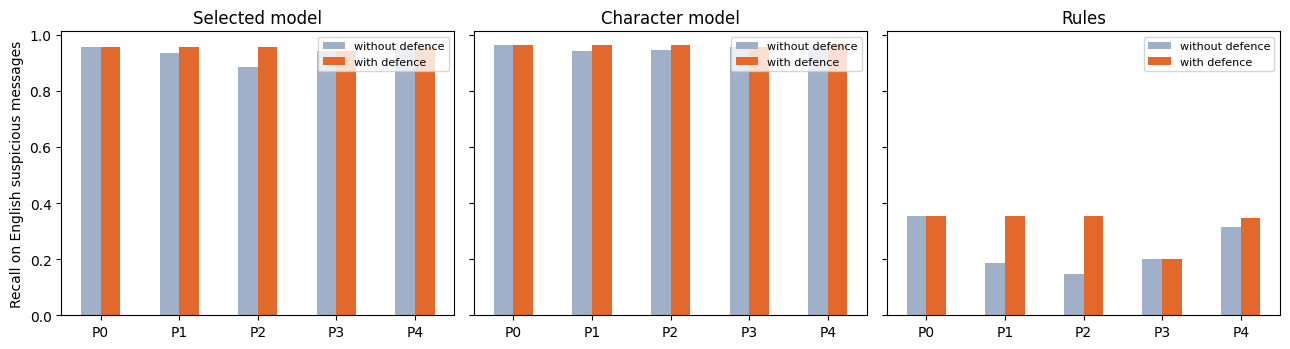

In [4]:
import matplotlib.pyplot as plt

results = pd.read_csv(ROOT / "reports" / "obfuscation_results.csv")
display(results.round(3))
figure, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
names = {"M": "Selected model", "C": "Character model", "R": "Rules"}
for axis, (system, part) in zip(axes, results.groupby("system", sort=False)):
    table = part.pivot(index="perturbation", columns="defence", values="recall")[["N", "D"]]
    table.plot.bar(ax=axis, color=["#9FB0C8", "#E2692B"], rot=0)
    axis.set_title(names[system])
    axis.set_xlabel("")
    axis.legend(["without defence", "with defence"], fontsize=8)
axes[0].set_ylabel("Recall on English suspicious messages")
plt.tight_layout()
plt.show()

## 4. Hypotheses

In [5]:
tests = pd.read_csv(ROOT / "reports" / "obfuscation_hypotheses.csv")
display(tests)
get = lambda system, defence, code: results.query("system == @system and defence == @defence and perturbation == @code")["recall"].item()
verdicts = pd.DataFrame([
    {"hypothesis": "H1", "measure": get("M", "N", "P0") - get("M", "N", "P1"), "confirmed": get("M", "N", "P0") - get("M", "N", "P1") >= 0.10},
    {"hypothesis": "H2", "measure": tests.query("hypothesis == 'H2'")["low"].min(), "confirmed": bool((tests.query("hypothesis == 'H2'")["low"] > 0).all())},
    {"hypothesis": "H3", "measure": max(abs(get("M", "D", c) - get("M", "N", "P0")) for c in ["P1", "P2"]),
     "confirmed": all(abs(get("M", "D", c) - get("M", "N", "P0")) <= 0.02 for c in ["P1", "P2"])},
    {"hypothesis": "H4", "measure": tests.query("hypothesis == 'H4'")["value"].item(), "confirmed": tests.query("hypothesis == 'H4'")["value"].item() >= -0.005},
])
display(verdicts.round(4))

,hypothesis,perturbation,statistic,value,low,high
0,H2,P1,loss of M minus loss of C,0.0012,-0.0146,0.0169
1,H2,P2,loss of M minus loss of C,0.0526,0.0354,0.0698
2,H2,P3,loss of M minus loss of C,0.0084,-0.0024,0.0189
3,H4,P0,precision of M with D minus without D,0.0000,0.0000,0.0000


,hypothesis,measure,confirmed
0,H1,0.0239,False
1,H2,-0.0146,False
2,H3,0.0000,True
3,H4,0.0000,True


**Findings**

- H1 is refuted. Look-alike letters cost the selected model only 0.024 of recall, because the masked tokens of numbers, amounts and links are not affected.
- H2 is refuted. Character n-grams resist invisible characters much better, a gap of 0.053, but not look-alike letters or digits.
- H3 and H4 are confirmed. The defence restores the clean recall without changing precision, so it was adopted in `normalize`, and the retrained model has identical test scores.
- The rules lose up to 0.207 of recall without defence. An attacker could erase the evidence shown to the user while the model still detects the message.